# Étape 2 — Corrections du choix des fenêtres

Ce notebook **complète** [`laura_hep_groupe.ipynb`](laura_hep_groupe.ipynb) (haute vs basse) et
[`laura_hep_repos.ipynb`](laura_hep_repos.ipynb) (vidéos vs repos), qui restent inchangés pour garder
la trace de l'analyse initiale. Il corrige trois faiblesses du choix des fenêtres :

| # | Problème dans l'analyse initiale | Correction ici |
|---|---|---|
| 1 | « Le HEP existe » testé dans des fenêtres choisies là où vrais et faux battements différaient : **circulaire** | test par clusters vrais vs faux battements, **sans fenêtre** |
| 2 | Vidéos vs repos : fenêtres définies sur les **vidéos seules**, donc favorables à une des deux conditions | fenêtres définies sur la **moyenne des deux conditions** |
| 3 | Latence cherchée dans 200–600 ms alors que la composante négative commence vers 150 ms : **début coupé** | latence cherchée sur **toute la composante** |

**Règle des fenêtres (fixée avant de regarder les différences)** : pour chaque comparaison A vs B, on
prend la moyenne du groupe de (A + B) / 2 ; la composante négative est la zone autour de son minimum
(entre 50 et 600 ms) comprise entre deux passages par zéro ; la composante positive, la zone autour du
maximum qui suit. Aucune fenêtre ne commence avant **100 ms** (complexe QRS). Cette borne a été
ajoutée après une première version de la règle : sans elle, la courbe ne repassant pas par zéro entre
le pic R et le HEP, la fenêtre « négative » englobait l'artefact du pic R (fenêtres 52–361 et 0–379 ms).
Comme (A + B) / 2 ne favorise ni A ni B, la fenêtre ne biaise pas la comparaison
(méthode dite de « localisation sur les conditions regroupées »).

Mêmes données que les notebooks précédents ; rien n'est recalculé sur les enregistrements bruts.

In [1]:
import os
os.environ.setdefault("HABS_DATA", r"C:\Users\ehren\habs-data")   # à adapter sur ta machine

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from scipy import stats
from mne.stats import permutation_cluster_1samp_test
from hep_utils import mean_amp, frac_area_latency, _montage

ROOT = Path(os.environ["HABS_DATA"]) / "derivatives"
plt.rcParams["figure.dpi"] = 90
MIN_BEATS = 50

rv = pd.read_csv(ROOT / "hep" / "resume.csv")
subj_v = sorted(rv[(rv.battements_basse >= MIN_BEATS) & (rv.battements_haute >= MIN_BEATS)].subj)
V = {s: dict(np.load(ROOT / "hep" / f"{s}.npz")) for s in subj_v}
rr_ = pd.read_csv(ROOT / "hep_repos" / "resume_repos.csv")
subj_r = sorted(set(subj_v) & set(rr_[rr_.battements_repos_yo >= MIN_BEATS].subj))
R = {s: dict(np.load(ROOT / "hep_repos" / f"{s}.npz")) for s in subj_r}

f = V[subj_v[0]]
times, ch_names = f["times"], [str(c) for c in f["ch_names"]]
cl_idx = [ch_names.index(str(c)) for c in f["cluster"]]
cl = lambda x: x[cl_idx].mean(0)
info = mne.create_info(ch_names, 1 / (times[1] - times[0]), "eeg"); info.set_montage(_montage(), on_missing="ignore")
adj, _ = mne.channels.find_ch_adjacency(info, "eeg")

def video_all(d):
    n = {c: (d["wave_cond"] == c).sum() for c in ["basse", "moyenne", "haute"]}
    return sum(d[f"evoked_{c}"] * n[c] for c in n if f"evoked_{c}" in d) / sum(n.values())

def cluster_test(diffs, label, tmax=0.6, step=4, n_perm=2000):
    """Test par clusters (électrodes × temps, 0–tmax) sur une liste de différences (électrodes, temps)."""
    keep = (times >= 0) & (times <= tmax)
    X = np.array([d[:, keep][:, ::step].T for d in diffs])
    T, clusters, pv, _ = permutation_cluster_1samp_test(X, n_permutations=n_perm, adjacency=adj, seed=0,
                                                        out_type="mask", verbose=False)
    tt = times[keep][::step]
    print(f"{label} : {len(clusters)} clusters, plus petit p = {pv.min() if len(pv) else float('nan'):.4f}")
    for i in np.argsort(pv)[:3]:
        tm, chm = np.where(clusters[i]); sgn = "+" if T[clusters[i]].mean() > 0 else "−"
        print(f"   p = {pv[i]:.4f} ({sgn}) : {tt[tm.min()]*1000:.0f}–{tt[tm.max()]*1000:.0f} ms, {len(set(chm))} électrodes "
              f"({', '.join(sorted(set(np.array(ch_names)[chm]))[:10])}{'…' if len(set(chm)) > 10 else ''})")
    return T, clusters, pv, tt

QRS_END = 0.10   # s : rien avant 100 ms (complexe QRS, artefact du pic R)

def comp_window(w, sign, after=QRS_END, tmax=0.6):
    """Zone autour de l'extrême de signe `sign` (après `after`), bornée par les passages par zéro,
    sans descendre sous QRS_END."""
    m = (times >= after) & (times <= tmax)
    i = np.where(m)[0][np.argmax(sign * w[m])]
    a = i
    while a > 0 and sign * w[a - 1] > 0 and times[a - 1] >= QRS_END: a -= 1
    b = i
    while b < len(w) - 1 and sign * w[b + 1] > 0 and times[b + 1] <= tmax: b += 1
    return times[a], times[b]

def jackknife_lat(A, B, win, pol):
    """Latence (aire fractionnelle 50 %) de B − A et jackknife sur les participants."""
    lat = lambda w: frac_area_latency(w, times, win=win, polarity=pol)
    n = len(A)
    full = lat(B.mean(0)) - lat(A.mean(0))
    loo = np.array([lat(np.delete(B, i, 0).mean(0)) - lat(np.delete(A, i, 0).mean(0)) for i in range(n)])
    se = np.sqrt((n - 1) / n * ((loo - loo.mean()) ** 2).sum())
    t = full / se if se > 0 else np.nan
    return lat(A.mean(0)), lat(B.mean(0)), full, se, t, 2 * stats.t.sf(abs(t), n - 1)

def compare(A, B, nameA, nameB):
    """Fenêtres sur (A + B) / 2, puis amplitude et latence B − A. A, B : (participants, temps)."""
    pooled = (A.mean(0) + B.mean(0)) / 2
    neg = comp_window(pooled, -1)
    pos = comp_window(pooled, +1, after=neg[1])
    rows = []
    for name, win in [("négative", neg), ("positive", pos)]:
        d = mean_amp(B, times, win) - mean_amp(A, times, win)
        t, p = stats.ttest_1samp(d, 0)
        rows.append({"composante": name, "fenêtre (ms)": f"{win[0]*1000:.0f}–{win[1]*1000:.0f}",
                     f"{nameA} (µV)": mean_amp(A, times, win).mean(), f"{nameB} (µV)": mean_amp(B, times, win).mean(),
                     f"{nameB} − {nameA}": d.mean(), "t": t, "p": p, "Wilcoxon p": stats.wilcoxon(d).pvalue})
    la, lb, dl, se, t, p = jackknife_lat(A, B, neg, -1)
    print(f"Latence de la composante négative ({neg[0]*1000:.0f}–{neg[1]*1000:.0f} ms) : {nameA} {la*1000:.0f} ms, "
          f"{nameB} {lb*1000:.0f} ms ; différence {dl*1000:+.0f} ms, ET jackknife {se*1000:.0f} ms, t({len(A)-1}) = {t:.2f}, p = {p:.3f}")
    return pd.DataFrame(rows).round(3), neg, pos

def plot_cmp(curves, neg, pos, title):
    fig, ax = plt.subplots(figsize=(10, 3.4))
    for x, lab, col in curves:
        m, se = x.mean(0), x.std(0, ddof=1) / np.sqrt(len(x))
        ax.fill_between(times * 1000, m - 1.96 * se, m + 1.96 * se, color=col, alpha=.18)
        ax.plot(times * 1000, m, color=col, label=f"{lab} (n = {len(x)})")
    ax.axvspan(neg[0] * 1000, neg[1] * 1000, color="C0", alpha=.07, label="fenêtre négative")
    ax.axvspan(pos[0] * 1000, pos[1] * 1000, color="C3", alpha=.07, label="fenêtre positive")
    ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5, ls="--")
    ax.set_xlabel("ms après le pic R"); ax.set_ylabel("µV"); ax.legend(fontsize=8); ax.set_title(title)
    plt.tight_layout(); plt.show()

## Correction 1 — Le HEP existe-t-il ? (sans fenêtre)

Test par clusters sur tout le scalp, 0–600 ms : vrais battements (toutes vidéos) − faux battements,
pour chaque participant. Aucune fenêtre ni électrode choisie à l'avance : le test n'est plus circulaire.

C:\Users\ehren\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Vrais − faux battements (22 participants) : 21 clusters, plus petit p = 0.0005
   p = 0.0005 (+) : 160–596 ms, 32 électrodes (C1, C2, C3, CP1, CP2, CP3, CP4, CP5, FC1, FCz…)
   p = 0.0040 (−) : 148–452 ms, 26 électrodes (AF3, AF4, AF7, AF8, C4, C6, F1, F10, F2, F3…)
   p = 0.0565 (−) : 20–132 ms, 25 électrodes (C3, CP1, CP2, CP3, CP6, O1, O2, P1, P10, P2…)


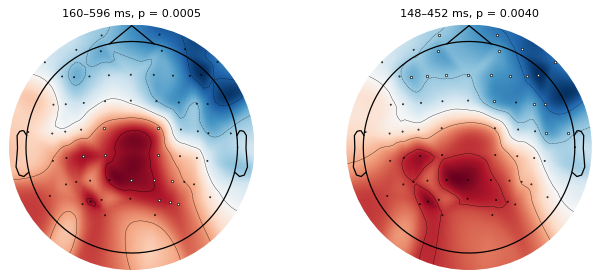

In [2]:
T1, cl1, pv1, tt1 = cluster_test([video_all(V[s]) - V[s]["surrogate"] for s in subj_v],
                                 f"Vrais − faux battements ({len(subj_v)} participants)")
sig = [i for i in np.argsort(pv1) if pv1[i] < 0.05]
if sig:
    fig, axs = plt.subplots(1, min(len(sig), 3), figsize=(4 * min(len(sig), 3), 3.2), squeeze=False)
    for ax, i in zip(axs[0], sig[:3]):
        mask = cl1[i].T; tm = np.where(mask.any(0))[0]
        ev = mne.EvokedArray(T1.T, mne.create_info(ch_names, 250, "eeg"), tmin=tt1[0]); ev.set_montage(_montage(), on_missing="ignore")
        ev.plot_topomap(times=[tt1[tm].mean()], average=tt1[tm[-1]] - tt1[tm[0]] + 0.004, mask=mask, axes=ax,
                        units="t", scalings=1, colorbar=False, show=False)
        ax.set_title(f"{tt1[tm[0]]*1000:.0f}–{tt1[tm[-1]]*1000:.0f} ms, p = {pv1[i]:.4f}", fontsize=9)
    plt.tight_layout(); plt.show()

## Corrections 2 et 3 — Activation haute vs basse

Fenêtres définies sur la moyenne (haute + basse) / 2 ; latence cherchée sur toute la composante
négative ainsi définie.

Latence de la composante négative (100–361 ms) : basse 229 ms, haute 229 ms ; différence +0 ms, ET jackknife 13 ms, t(21) = 0.00, p = 1.000


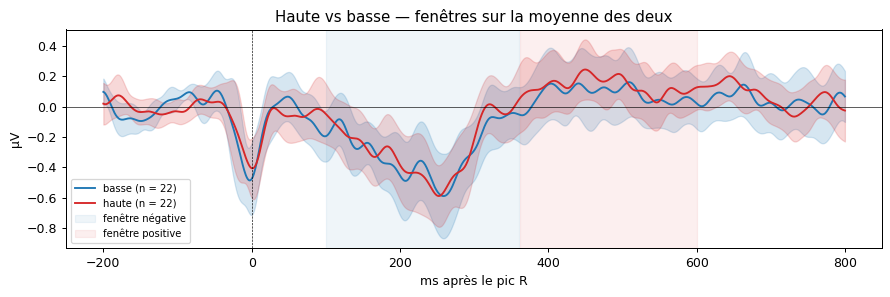

,composante,fenêtre (ms),basse (µV),haute (µV),haute − basse,t,p,Wilcoxon p
0,négative,100–361,-0.294,-0.270,0.024,0.284,0.779,0.874
1,positive,362–600,0.079,0.135,0.056,0.653,0.521,0.406


In [3]:
hi_w = np.array([cl(V[s]["evoked_haute"]) for s in subj_v]); lo_w = np.array([cl(V[s]["evoked_basse"]) for s in subj_v])
tab_hb, neg_hb, pos_hb = compare(lo_w, hi_w, "basse", "haute")
plot_cmp([(lo_w, "basse", "C0"), (hi_w, "haute", "C3")], neg_hb, pos_hb, "Haute vs basse — fenêtres sur la moyenne des deux")
tab_hb

## Corrections 2 et 3 — Vidéos vs repos yeux ouverts

Fenêtres définies sur la moyenne (vidéos + repos) / 2, et non plus sur les vidéos seules.

Latence de la composante négative (100–379 ms) : repos YO 235 ms, vidéos 229 ms ; différence -6 ms, ET jackknife 12 ms, t(15) = -0.51, p = 0.618


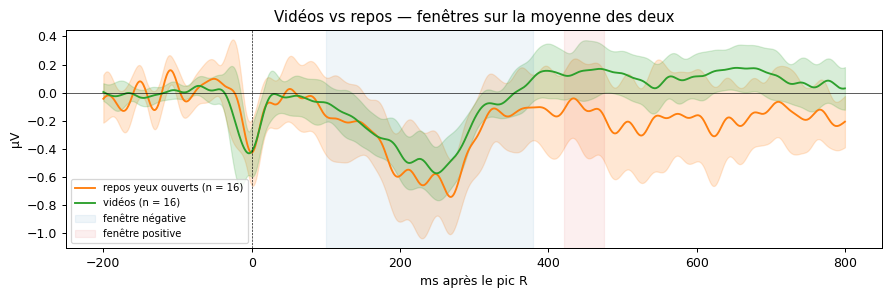

,composante,fenêtre (ms),repos YO (µV),vidéos (µV),vidéos − repos YO,t,p,Wilcoxon p
0,négative,100–379,-0.363,-0.259,0.104,1.042,0.314,0.144
1,positive,421–475,-0.099,0.149,0.249,1.441,0.170,0.298


In [4]:
vid = np.array([cl(video_all(V[s])) for s in subj_r]); yo = np.array([cl(R[s]["evoked_repos_yo"]) for s in subj_r])
tab_vr, neg_vr, pos_vr = compare(yo, vid, "repos YO", "vidéos")
plot_cmp([(yo, "repos yeux ouverts", "C1"), (vid, "vidéos", "C2")], neg_vr, pos_vr, "Vidéos vs repos — fenêtres sur la moyenne des deux")
tab_vr

## Avant / après

Comparaison des résultats initiaux (notebooks précédents) et corrigés. Les tests par clusters des
notebooks précédents n'utilisaient pas de fenêtre : ils ne sont pas concernés par ces corrections.

In [5]:
avant_apres = pd.DataFrame([
    {"comparaison": "haute − basse", "mesure": "amplitude négative",
     "avant": "150–320 ms : +0,02 µV, p = 0,83", "après": f"{tab_hb.iloc[0]['fenêtre (ms)']} ms : {tab_hb.iloc[0]['haute − basse']:+.2f} µV, p = {tab_hb.iloc[0]['p']:.2f}"},
    {"comparaison": "haute − basse", "mesure": "amplitude positive",
     "avant": "380–550 ms : +0,05 µV, p = 0,62", "après": f"{tab_hb.iloc[1]['fenêtre (ms)']} ms : {tab_hb.iloc[1]['haute − basse']:+.2f} µV, p = {tab_hb.iloc[1]['p']:.2f}"},
    {"comparaison": "vidéos − repos", "mesure": "amplitude négative",
     "avant": "150–320 ms : +0,11 µV, p = 0,25", "après": f"{tab_vr.iloc[0]['fenêtre (ms)']} ms : {tab_vr.iloc[0]['vidéos − repos YO']:+.2f} µV, p = {tab_vr.iloc[0]['p']:.2f}"},
    {"comparaison": "vidéos − repos", "mesure": "amplitude positive",
     "avant": "380–550 ms : +0,30 µV, p = 0,10", "après": f"{tab_vr.iloc[1]['fenêtre (ms)']} ms : {tab_vr.iloc[1]['vidéos − repos YO']:+.2f} µV, p = {tab_vr.iloc[1]['p']:.2f}"},
])
avant_apres

,comparaison,mesure,avant,après
0,haute − basse,amplitude négative,"150–320 ms : +0,02 µV, p = 0,83","100–361 ms : +0.02 µV, p = 0.78"
1,haute − basse,amplitude positive,"380–550 ms : +0,05 µV, p = 0,62","362–600 ms : +0.06 µV, p = 0.52"
2,vidéos − repos,amplitude négative,"150–320 ms : +0,11 µV, p = 0,25","100–379 ms : +0.10 µV, p = 0.31"
3,vidéos − repos,amplitude positive,"380–550 ms : +0,30 µV, p = 0,10","421–475 ms : +0.25 µV, p = 0.17"


## Bilan des corrections

1. **Le HEP existe, sans circularité** : le test par clusters sans fenêtre trouve une réponse positive
   centro-pariétale (160–596 ms, p = 0,0005) et une réponse négative fronto-latérale (148–452 ms,
   p = 0,004) aux vrais battements par rapport aux faux. L'existence du HEP ne dépend donc plus d'un
   choix de fenêtre.
2. **Haute vs basse : conclusion inchangée.** Fenêtres définies sur la moyenne des deux conditions
   (100–361 et 362–600 ms) : aucune différence d'amplitude (p = 0,78 et 0,52) ni de latence
   (229 ms dans les deux cas, différence 0 ± 13 ms).
3. **Vidéos vs repos : conclusion inchangée, et la « tendance » sur la latence disparaît.** Avec la
   fenêtre initiale (200–600 ms), le repos semblait plus tardif (−38 ± 31 ms) ; en cherchant la latence
   sur toute la composante (100–379 ms), l'écart n'est plus que de −6 ± 12 ms (p = 0,62). La
   tendance venait donc de la coupure du début de la composante, pas d'un vrai décalage.

**À retenir pour le rapport** : les conclusions négatives (pas d'effet de l'activation, pas d'effet
vidéos vs repos) résistent aux corrections. La correction 3 montre aussi qu'un mauvais choix de
fenêtre peut fabriquer une tendance de latence : c'est un argument pour la règle utilisée ici
(fenêtres définies sur les conditions regroupées, toute la composante, rien avant 100 ms).

**Limite restante** : le groupe d'électrodes fronto-central est fixé d'après la littérature, alors que
le HEP de ces données est surtout centro-pariétal (positif) et fronto-latéral (négatif). Les tests par
clusters, qui couvrent tout le scalp, compensent cette limite pour les conclusions.